# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  
---

# Pertemuan VI

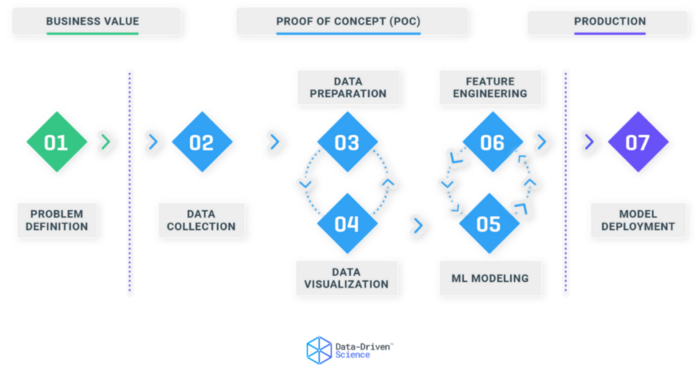

Gambar di atas menunjukkan tahapan yang Anda perlu lakukan ketika ingin membangun sebuah model *artificial intelligence*. 
Pada minggu ini, Anda akan melakukan fase data cleansing atau pembersihan data. Tahapan ini biasanya dilakukan sebelum Anda melakukan tahapan EDA yang telah Anda pelajari sebelumnya. Tahapan ini perlu dilakukan jika data yang Anda miliki tidak 'bersih', sehingga perlu dilakukan pemrosesan terlebih dahulu (tahapan pre-processing) sebelum data tersebut masuk kedalam algoritma pembangunan model. 

Materi praktikum ini dibagi menjadi 2 bagian dengan menggunakan dua dataset yang berbeda. Adapun operasi akan Anda lakukan antara lain:
* Melihat bentuk data (shape) dari train set dan test set.
* Cek data NaN, bila ada maka hapus/drop data NaN tersebut.
* Cek outliers, bila ada maka hapus/drop outliers tersebut.
* Melakukan konversi jenis kolom yang relevan.
* Melakukan transformasi terhadap data yang bersifat kategori.

Operasi yang Anda lakukan pada tahapan pembersihan data sangat bergantung pada karakteristik permasalahan, karakter data, serta jenis data yang terdapat dalam dataset Anda. Sebagai referensi, berikut bagan dari berbagai macam tipe data yang mungkin Anda temui dalam sebuah dataset. 



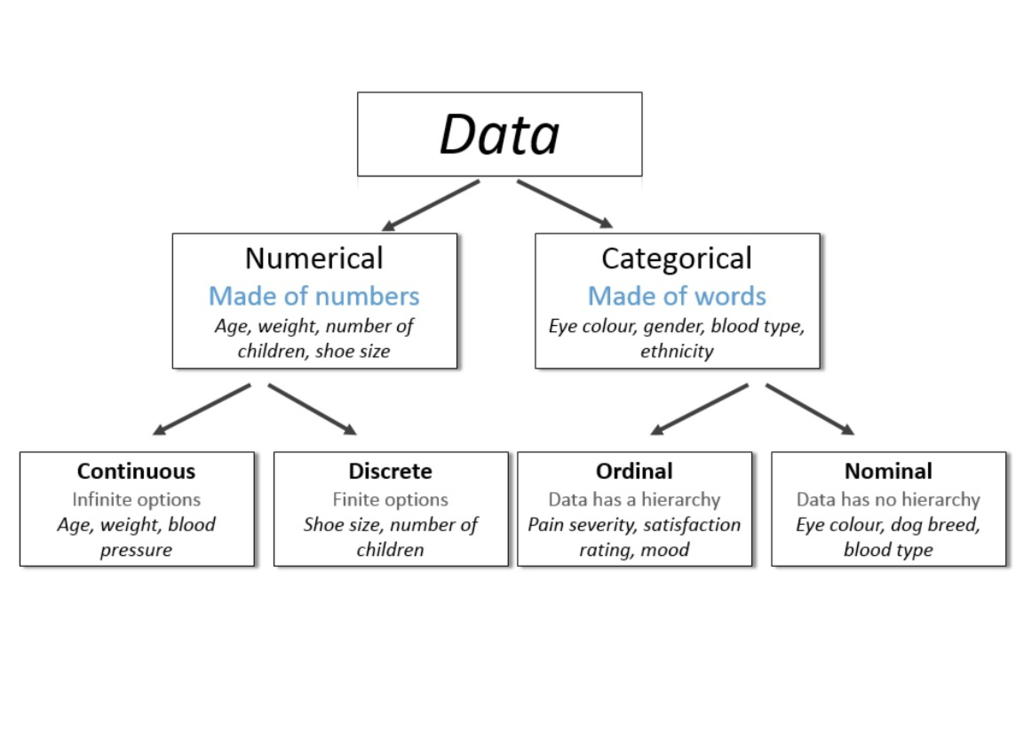

## Dataset 

Dataset yang akan Anda gunakan pada praktikum kali ini adalah dataset komposisi beton (concrete).

### Overview Dataset
"Data Pembuatan Semen (Cement Manufacturing)"

Beton merupakan material terpenting dalam teknik sipil. Kuat tekan beton adalah fungsi yang sangat nonlinier dari umur dan bahan. Bahan-bahan tersebut antara lain semen, terak tanur tinggi, fly ash, air, superplasticizer, agregat kasar, dan agregat halus. Dataset ini berisi data mengenai kekuatan semen, bahan penyusun dan waktu campuran.

Kekuatan tekan beton (MPa) untuk campuran tertentu di bawah umur tertentu (hari) ditentukan dari informasi laboratorium. Data ini merupakan data (tidak diskalakan). Data memiliki 8 variabel input kuantitatif, dan 1 variabel output kuantitatif, dan 1030 kejadian (pengamatan). 

<br>Dataset ini berisikan beberapa kategori sebagai berikut:
* cement (kg)
* slag (blast furnace slag, kg)
* ash (fly ash, kg)
* water (kg)
* superplastic (superplasticizer, kg)
* coarseagg (coarse aggregate, kg)
* fineagg (fine aggregate, kg)
* age (days, 1-365)
* strength (Concrete compressive strength, MPa)

## Import Libraries

In [1]:
%matplotlib inline
import numpy as np 
import pandas as pd 
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt

## Membaca Dataset 

In [2]:
# Load data train dan test ke dalam pandas dataframe
# Tautan dataset: https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv
concrete = pd.read_csv("https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv")

In [3]:
# Menghasilkan jumlah baris dan jumlah kolom (bentuk data) pada data train dengan fungsi .shape
concrete.shape

(1030, 9)

In [4]:
# Menampilkan 10 data teratas
concrete.head(10)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,NaN,203.5,NaN,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,NaN,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,NaN,228.0,NaN,932.0,670.0,28,45.85
4,154.8,183.4,NaN,193.3,9.1,1047.4,696.7,28,18.29
5,255.0,NaN,NaN,192.0,NaN,889.8,945.0,90,21.86
6,166.8,250.2,NaN,203.5,NaN,975.6,692.6,7,15.75
7,251.4,NaN,118.3,188.5,6.4,1028.4,757.7,56,36.64
8,296.0,NaN,NaN,192.0,NaN,1085.0,765.0,28,21.65
9,155.0,184.0,143.0,194.0,9.0,880.0,699.0,28,28.99


In [5]:
# Mengetahui statistika data untuk data numeric seperti count, mean, standard deviation, maximum, mininum, dan quartile dengan fungsi. describe.
concrete.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,559.000000,464.000000,1030.000000,651.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,136.158676,120.288793,181.567282,9.816897,972.918932,773.580485,45.662136,35.817961
std,104.506364,72.351823,33.675470,21.354219,4.580328,77.753954,80.175980,63.169912,16.705742
min,102.000000,11.000000,24.500000,121.800000,1.700000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,95.000000,97.850000,164.900000,6.950000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,135.700000,121.400000,185.000000,9.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,189.000000,141.000000,192.000000,11.600000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


## Missing Values
Missing values adalah nilai yang tidak terdefinisi di dataset. Bentuknya beragam, bisa berupa blank cell, ataupun simbol-simbol tertentu seperti NaN (Not a Number), NA (Not Available), ?, -, dan sebagainya. Missing values dapat menjadi masalah dalam analisis data serta tentunya dapat mempengaruhi hasil modelling machine learning.

### **Lakukan pemeriksaan dan perubahan data kosong setiap kolom pada data train:**

In [6]:
# Cek nilai yang hilang / missing values di dalam data train
concrete.isnull().sum().sort_values(ascending=False)

ash             566
slag            471
superplastic    379
cement            0
water             0
coarseagg         0
fineagg           0
age               0
strength          0
dtype: int64

<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FIKTI dan FTI <br>(Informatika dan Teknik Elektro)</h1> 

<div style="text-align: center;">
  <h3>Fakultas Ilmu Komputer dan Teknologi Informasi (FIKTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Sistem Informasi</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Sistem Komputer</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Manajemen Informatika</td>
      <td>Diploma Tiga</td>
    </tr>
    <tr>
      <td>4</td>
      <td>Teknik Komputer</td>
      <td>Diploma Tiga</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Informatika</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Elektro</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum
1. Lakukan teknik data cleaning untuk data yang bernilai NaN pada Dataset concrete.  (Ubah data bernilai NaN menjadi 0).
2. Transformasikan data pada kolom <code>'strength'</code> menjadi kolom baru bernama <code>'category'</code>, dengan ketentuan:
   1. Jika nilai >= 65 = 'Hard'
   2. Jika nilai >= 40 = 'Medium'
   3. Jika nilai < 40 = 'Light'
3. Lakukan analisis histogram untuk pengaruh kolom <code>'age'</code> terhadap kolom <code>'strength'</code>, apakah yang dapat Anda simpulkan?
4. Cari tahu komposisi concrete yang memiliki kekuatan tertinggi dan terendah.
5. Berikan kesimpulan akhir anda terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan.

## JAWABAN ##

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code># CODE HERE <...></code> digantikan dengan code python sesuai dengan perintah. <br>
    Pada bagian <code># Ketik disini</code> cukup diketikkan jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia.
    </div>

### No 1.

In [7]:
# Lakukan teknik data cleaning untuk data yang bernilai NaN pada Dataset concrete. (Ubah data bernilai NaN menjadi 0)

# 1. Cek jumlah missing values SEBELUM cleaning
missing_sebelum = concrete.isnull().sum().sort_values(ascending=False)
print("Jumlah missing values sebelum cleaning:")
print(missing_sebelum[missing_sebelum > 0])
print(f"\nTotal missing values sebelum cleaning: {concrete.isnull().sum().sum()}")

# 2. Ubah seluruh nilai NaN menjadi 0
concrete = concrete.fillna(0)

# 3. Verifikasi hasil cleaning
print(f"\nTotal missing values setelah cleaning: {concrete.isnull().sum().sum()}")
print("\nJumlah missing values per kolom setelah cleaning:")
print(concrete.isnull().sum().sort_values(ascending=False))

concrete.head()

Jumlah missing values sebelum cleaning:
ash             566
slag            471
superplastic    379
dtype: int64

Total missing values sebelum cleaning: 1416

Total missing values setelah cleaning: 0

Jumlah missing values per kolom setelah cleaning:
cement          0
slag            0
ash             0
water           0
superplastic    0
coarseagg       0
fineagg         0
age             0
strength        0
dtype: int64


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,0.0,203.5,0.0,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,0.0,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
4,154.8,183.4,0.0,193.3,9.1,1047.4,696.7,28,18.29


### No 2.

In [8]:
# Transformasikan data pada kolom strength menjadi kolom baru bernama 'category'

def kategori_strength(nilai):
    """Mengubah nilai strength (MPa) menjadi kategori kekuatan beton."""
    if nilai >= 65:
        return 'Hard'
    elif nilai >= 40:
        return 'Medium'
    else:
        return 'Light'

concrete['category'] = concrete['strength'].apply(kategori_strength)

# Cek hasil transformasi
print("Jumlah data per kategori:")
print(concrete['category'].value_counts())
print("\nPersentase data per kategori (%):")
print((concrete['category'].value_counts(normalize=True) * 100).round(2))
print("\nRentang nilai strength tiap kategori:")
print(concrete.groupby('category')['strength'].agg(['min', 'max']))

concrete[['strength', 'category']].head(10)

Jumlah data per kategori:
category
Light     651
Medium    315
Hard       64
Name: count, dtype: int64

Persentase data per kategori (%):
category
Light     63.20
Medium    30.58
Hard       6.21
Name: proportion, dtype: float64

Rentang nilai strength tiap kategori:
            min    max
category              
Hard      65.20  82.60
Light      2.33  39.94
Medium    40.06  64.90


,strength,category
0,29.89,Light
1,23.51,Light
2,29.22,Light
3,45.85,Medium
4,18.29,Light
5,21.86,Light
6,15.75,Light
7,36.64,Light
8,21.65,Light
9,28.99,Light


### No 3.

Statistik strength berdasarkan umur (age):
     jumlah  rata_rata  median  minimum  maksimum
age                                              
1         2       9.46    9.46     6.27     12.64
3       134      18.98   15.72     2.33     41.64
7       126      26.05   21.65     7.51     59.09
14       62      28.75   26.54    12.84     59.76
28      425      36.75   33.76     8.54     81.75
56       91      51.89   51.72    23.25     80.20
90       54      40.48   39.68    21.86     69.66
91       22      69.81   67.95    56.50     82.60
100      52      47.67   46.98    33.54     66.95
120       3      39.65   39.38    38.70     40.86
180      26      41.73   40.90    24.10     71.62
270      13      51.27   51.73    38.41     74.17
360       6      40.70   41.68    33.70     44.70
365      14      43.56   42.82    25.08     56.14

Korelasi Pearson  (age vs strength): 0.329
Korelasi Spearman (age vs strength): 0.596


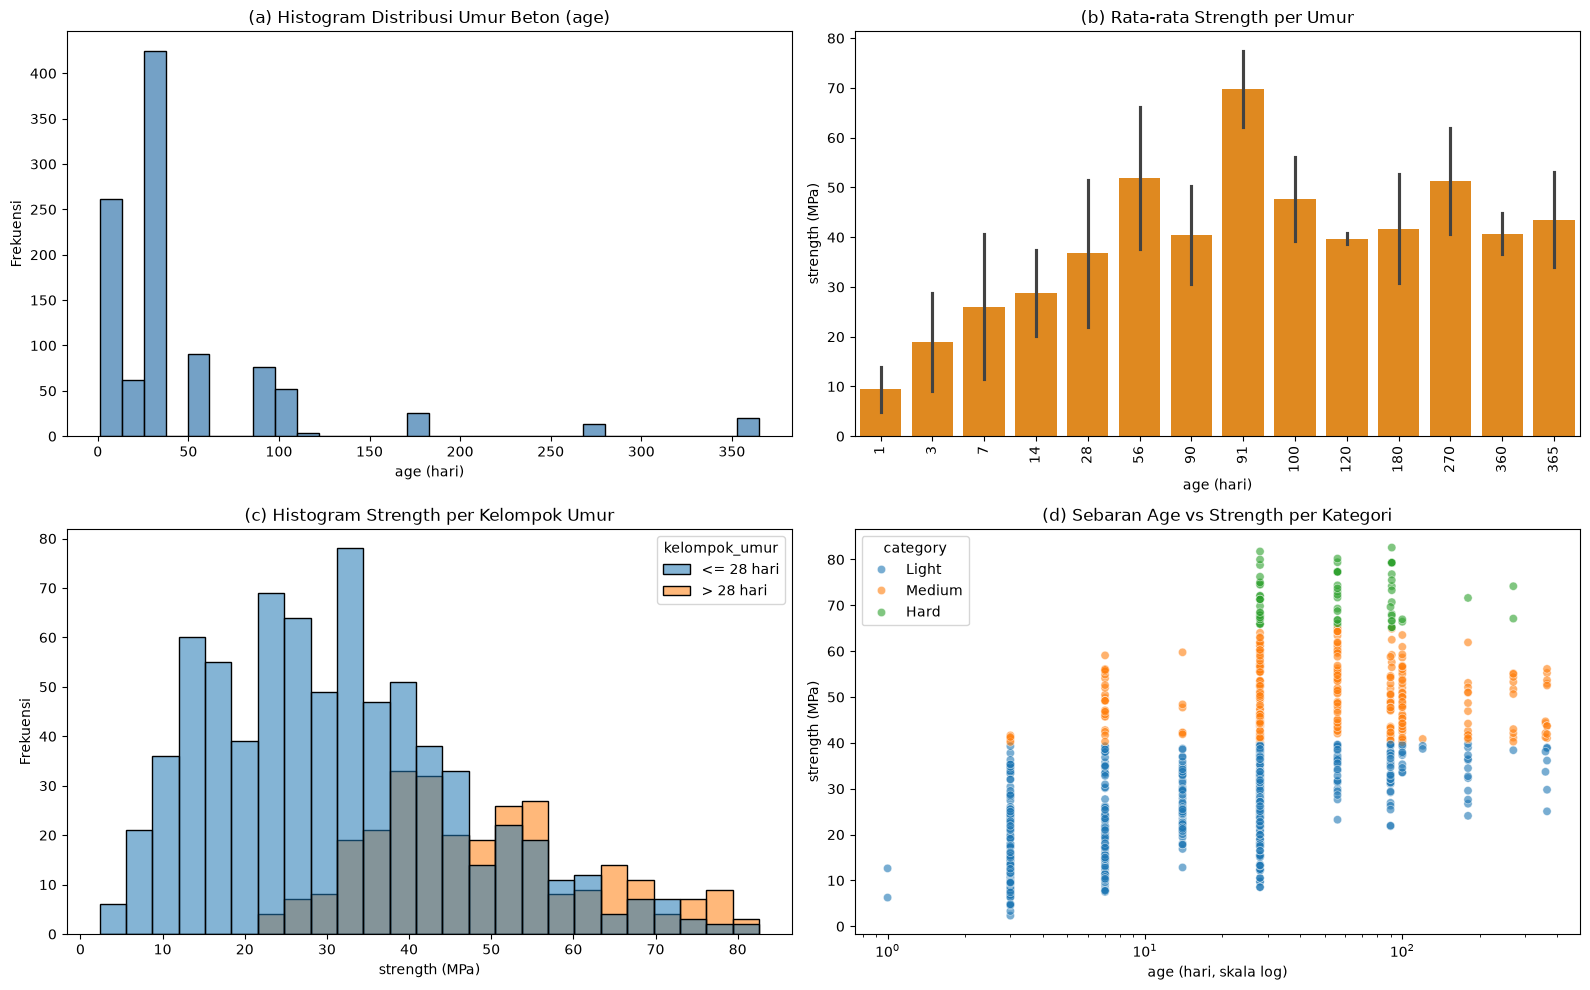

In [9]:
# Lakukan analisis histogram untuk pengaruh kolom age terhadap kolom strength
import matplotlib.pyplot as plt
import seaborn as sns

# --- Statistik ringkas strength berdasarkan umur ---
tabel_age = concrete.groupby('age')['strength'].agg(
    jumlah='count', rata_rata='mean', median='median', minimum='min', maksimum='max'
).round(2)
print("Statistik strength berdasarkan umur (age):")
print(tabel_age)

# --- Korelasi age terhadap strength ---
korelasi_pearson = concrete['age'].corr(concrete['strength'])
korelasi_spearman = concrete['age'].corr(concrete['strength'], method='spearman')
print(f"\nKorelasi Pearson  (age vs strength): {korelasi_pearson:.3f}")
print(f"Korelasi Spearman (age vs strength): {korelasi_spearman:.3f}")

# --- Visualisasi ---
concrete['kelompok_umur'] = np.where(concrete['age'] <= 28, '<= 28 hari', '> 28 hari')
urutan_age = sorted(concrete['age'].unique())

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (a) Histogram distribusi umur
sns.histplot(data=concrete, x='age', bins=30, color='steelblue', ax=axes[0, 0])
axes[0, 0].set_title('(a) Histogram Distribusi Umur Beton (age)')
axes[0, 0].set_xlabel('age (hari)')
axes[0, 0].set_ylabel('Frekuensi')

# (b) Rata-rata strength untuk setiap umur
sns.barplot(data=concrete, x='age', y='strength', order=urutan_age,
            errorbar='sd', color='darkorange', ax=axes[0, 1])
axes[0, 1].set_title('(b) Rata-rata Strength per Umur')
axes[0, 1].set_xlabel('age (hari)')
axes[0, 1].set_ylabel('strength (MPa)')
axes[0, 1].tick_params(axis='x', rotation=90)

# (c) Histogram strength berdasarkan kelompok umur
sns.histplot(data=concrete, x='strength', hue='kelompok_umur', bins=25,
             alpha=0.55, ax=axes[1, 0])
axes[1, 0].set_title('(c) Histogram Strength per Kelompok Umur')
axes[1, 0].set_xlabel('strength (MPa)')
axes[1, 0].set_ylabel('Frekuensi')

# (d) Sebaran age vs strength (sumbu age logaritmik)
sns.scatterplot(data=concrete, x='age', y='strength', hue='category',
                hue_order=['Light', 'Medium', 'Hard'], alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('(d) Sebaran Age vs Strength per Kategori')
axes[1, 1].set_xlabel('age (hari, skala log)')
axes[1, 1].set_ylabel('strength (MPa)')

plt.tight_layout()
plt.show()

**Kesimpulan berdasarkan analisis histogram:**

1. **Sebaran umur (`age`) tidak merata (right-skewed).** Pengujian paling banyak dilakukan pada umur **28 hari (425 data)**, 3 hari (134), 7 hari (126), 56 hari (91), dan 14 hari (62). Data umur 90 hari ke atas jumlahnya sangat sedikit, sehingga histogram umur menumpuk di umur muda dan berekor panjang ke umur tua.
2. **Rata-rata `strength` meningkat seiring bertambahnya umur:** 9,46 MPa (1 hari) → 18,98 MPa (3 hari) → 26,05 MPa (7 hari) → 28,75 MPa (14 hari) → 36,75 MPa (28 hari) → 51,89 MPa (56 hari) → 69,81 MPa (91 hari). Pola ini sesuai proses hidrasi semen: beton semakin padat dan kuat ketika umurnya bertambah.
3. **Histogram `strength` kelompok umur > 28 hari bergeser ke kanan** (nilai strength lebih tinggi) dibanding kelompok ≤ 28 hari. Dengan demikian, umur terbukti berpengaruh terhadap `strength`.
4. **Korelasi `age`–`strength` positif tetapi tidak linear sempurna** (Pearson **0,329**; Spearman **0,596**). Hubungannya lebih menyerupai kurva logaritmik: kenaikan terbesar terjadi pada umur 1–28 hari, kemudian melandai setelah 28 hari.
5. **Setelah 90 hari, rata-rata `strength` tidak selalu lebih tinggi** (90 hari = 40,48 MPa; 100 hari = 47,67 MPa; 365 hari = 43,56 MPa) karena jumlah sampel sedikit dan komposisi campurannya berbeda-beda. Jadi, umur bukan satu-satunya faktor penentu dan harus dibaca bersama komposisi bahan penyusun beton.

### No 4.

In [10]:
# Komposisi concrete yang memiliki kekuatan tertinggi dan terendah
kolom_komposisi = ['cement', 'slag', 'ash', 'water', 'superplastic',
                   'coarseagg', 'fineagg', 'age', 'strength']

# Ambil baris dengan strength maksimum dan minimum
baris_tertinggi = concrete.loc[[concrete['strength'].idxmax()], kolom_komposisi]
baris_terendah = concrete.loc[[concrete['strength'].idxmin()], kolom_komposisi]

print(f"Kekuatan tertinggi : {concrete['strength'].max()} MPa")
print(f"Kekuatan terendah  : {concrete['strength'].min()} MPa\n")

print("=== Komposisi concrete dengan kekuatan TERTINGGI ===")
print(baris_tertinggi.T.to_string())
print("\n=== Komposisi concrete dengan kekuatan TERENDAH ===")
print(baris_terendah.T.to_string())

# Perbandingan berdampingan
perbandingan = pd.DataFrame({
    'Tertinggi': baris_tertinggi.iloc[0],
    'Terendah': baris_terendah.iloc[0]
})
print("\n=== Perbandingan komposisi ===")
print(perbandingan)

# Rasio air/semen (water-cement ratio) sebagai indikator tambahan
rasio_air_semen = perbandingan.loc['water'] / perbandingan.loc['cement']
print("\nRasio air/semen (water/cement):")
print(rasio_air_semen.round(3))

# Rata-rata komposisi per kategori sebagai pembanding
print("\n=== Rata-rata komposisi tiap kategori ===")
print(concrete.groupby('category')[kolom_komposisi].mean().round(2).T)

Kekuatan tertinggi : 82.6 MPa
Kekuatan terendah  : 2.33 MPa

=== Komposisi concrete dengan kekuatan TERTINGGI ===
                950
cement        389.9
slag          189.0
ash             0.0
water         145.9
superplastic   22.0
coarseagg     944.7
fineagg       755.8
age            91.0
strength       82.6

=== Komposisi concrete dengan kekuatan TERENDAH ===
                 230
cement        108.30
slag          162.40
ash             0.00
water         203.50
superplastic    0.00
coarseagg     938.20
fineagg       849.00
age             3.00
strength        2.33

=== Perbandingan komposisi ===
              Tertinggi  Terendah
cement            389.9    108.30
slag              189.0    162.40
ash                 0.0      0.00
water             145.9    203.50
superplastic       22.0      0.00
coarseagg         944.7    938.20
fineagg           755.8    849.00
age                91.0      3.00
strength           82.6      2.33

Rasio air/semen (water/cement):
Tertinggi    0.374

### No 5.

**Kesimpulan akhir terhadap pengaruh komposisi concrete:**

1. **Data cleaning.** Nilai NaN ditemukan pada kolom `slag` (471), `ash` (566), dan `superplastic` (379). Nilai tersebut diisi 0 karena merepresentasikan bahan yang tidak dipakai pada campuran (misalnya tanpa fly ash atau tanpa superplasticizer), sehingga seluruh **1.030 baris** menjadi bersih.
2. **Hasil transformasi `category`:** `Light` 651 data (**63,20%**), `Medium` 315 data (**30,58%**), dan `Hard` 64 data (**6,21%**). Artinya mayoritas campuran pada dataset ini menghasilkan beton berkekuatan rendah sampai sedang.
3. **Beton dengan kekuatan tertinggi (82,6 MPa)** menggunakan semen 389,9 kg, slag 189,0 kg, ash 0 kg, air 145,9 kg, superplasticizer 22,0 kg, agregat kasar 944,7 kg, agregat halus 755,8 kg, dan diuji pada umur 91 hari. Rasio air/semennya hanya **0,37**.
4. **Beton dengan kekuatan terendah (2,33 MPa)** hanya menggunakan semen 108,3 kg, slag 162,4 kg, ash 0 kg, air 203,5 kg, tanpa superplasticizer, agregat kasar 938,2 kg, agregat halus 849,0 kg, dan diuji pada umur 3 hari. Rasio air/semennya sangat tinggi, yaitu **1,88**.
5. **Faktor paling berpengaruh adalah jumlah semen dan rasio air/semen.** Rata-rata semen pada kategori `Hard` 397,13 kg dibanding `Light` 247,86 kg, sedangkan rata-rata air pada `Hard` 162,11 kg dibanding `Light` 185,31 kg. Semakin banyak semen dan semakin sedikit air (rasio air/semen rendah), semakin tinggi kekuatan beton.
6. **Superplasticizer juga berperan menaikkan kekuatan** karena mampu mengurangi pemakaian air: rata-ratanya 11,15 kg pada beton `Hard`, 7,91 kg pada `Medium`, dan hanya 4,89 kg pada `Light`.
7. **Fly ash (`ash`) dalam jumlah besar tanpa diimbangi semen** justru banyak terdapat pada beton `Light` (rata-rata 58,62 kg) dibanding beton `Hard` (16,67 kg), sehingga pada dataset ini fly ash dosis tinggi cenderung menurunkan kekuatan. Sebaliknya, agregat kasar dan agregat halus nilainya relatif stabil (sekitar 950–980 kg dan 760–780 kg) sehingga bukan pembeda utama kekuatan beton.
8. **Umur perawatan (`age`) berpengaruh positif dan cukup kuat secara monoton** (Spearman 0,596), dengan kenaikan terbesar pada 28 hari pertama. Namun umur bukan faktor tunggal, karena beton berumur tua tetap bisa lemah bila komposisi semennya sedikit dan airnya berlebihan.

**Kesimpulan:** kekuatan beton ditentukan oleh kombinasi komposisi, terutama **kadar semen**, **rasio air/semen**, dan **bahan tambahan** (superplasticizer, slag, fly ash), serta didukung oleh **umur perawatan**. Komposisi dengan semen tinggi, air terkendali, dan superplasticizer memadai menghasilkan beton `Hard`, sedangkan semen rendah dengan air berlebih menghasilkan beton `Light`.

<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FTSP dan FTI <br>(Teknik Industri, Teknik Mesin,dan Agroteknologi) </h1> 

<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Mesin</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>2</td>
      <td>Teknik Industri</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>3</td>
      <td>Agroteknologi</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknik Sipil dan Perencanaan (FTSP)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Aritektur</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Sipil</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Desain Interior</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum
1. Transformasikan data pada kolom <code>'strength'</code> menjadi kolom baru bernama <code>'category'</code>, dengan ketentuan: 
   1. Jika nilai >= 65 = 'Hard'
   2. Jika nilai >= 40 = 'Medium'
   3. Jika nilai < 40 = 'Light'
2. Lakukan analisis histogram untuk pengaruh kolom <code>'age'</code> terhadap kolom <code>'strength'</code>, apakah yang dapat Anda simpulkan?
3. Cari tahu komposisi concrete yang memiliki kekuatan tertinggi dan terendah.
4. Berikan kesimpulan akhir anda terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan.

## JAWABAN ##

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code># CODE HERE <...></code> digantikan dengan code python sesuai dengan perintah. <br>
    Pada bagian <code># Ketik disini</code> cukup diketikkan jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia.
    </div>

### No 1.

In [11]:
# Transformasikan data pada kolom 'strength' menjadi kolom baru bernama 'category'
import pandas as pd

# Pastikan tidak ada nilai NaN yang mengganggu proses transformasi
concrete = concrete.fillna(0)

# Kategorisasi memakai pd.cut dengan batas: < 40 = Light, 40-64,99 = Medium, >= 65 = Hard
concrete['category'] = pd.cut(
    concrete['strength'],
    bins=[-np.inf, 40, 65, np.inf],
    labels=['Light', 'Medium', 'Hard'],
    right=False
)

print("Jumlah data per kategori:")
print(concrete['category'].value_counts())
print("\nPersentase data per kategori (%):")
print((concrete['category'].value_counts(normalize=True).sort_index() * 100).round(2))
print("\nRentang nilai strength tiap kategori:")
print(concrete.groupby('category', observed=True)['strength'].agg(['min', 'max']))

concrete[['strength', 'category']].head(10)

Jumlah data per kategori:
category
Light     651
Medium    315
Hard       64
Name: count, dtype: int64

Persentase data per kategori (%):
category
Light     63.20
Medium    30.58
Hard       6.21
Name: proportion, dtype: float64

Rentang nilai strength tiap kategori:
            min    max
category              
Light      2.33  39.94
Medium    40.06  64.90
Hard      65.20  82.60


,strength,category
0,29.89,Light
1,23.51,Light
2,29.22,Light
3,45.85,Medium
4,18.29,Light
5,21.86,Light
6,15.75,Light
7,36.64,Light
8,21.65,Light
9,28.99,Light


### No 2.

Statistik strength berdasarkan umur:
     jumlah  rata_rata  minimum  maksimum
age                                      
1         2       9.46     6.27     12.64
3       134      18.98     2.33     41.64
7       126      26.05     7.51     59.09
14       62      28.75    12.84     59.76
28      425      36.75     8.54     81.75
56       91      51.89    23.25     80.20
90       54      40.48    21.86     69.66
91       22      69.81    56.50     82.60
100      52      47.67    33.54     66.95
120       3      39.65    38.70     40.86
180      26      41.73    24.10     71.62
270      13      51.27    38.41     74.17
360       6      40.70    33.70     44.70
365      14      43.56    25.08     56.14

Korelasi Pearson  age vs strength: 0.329
Korelasi Spearman age vs strength: 0.596


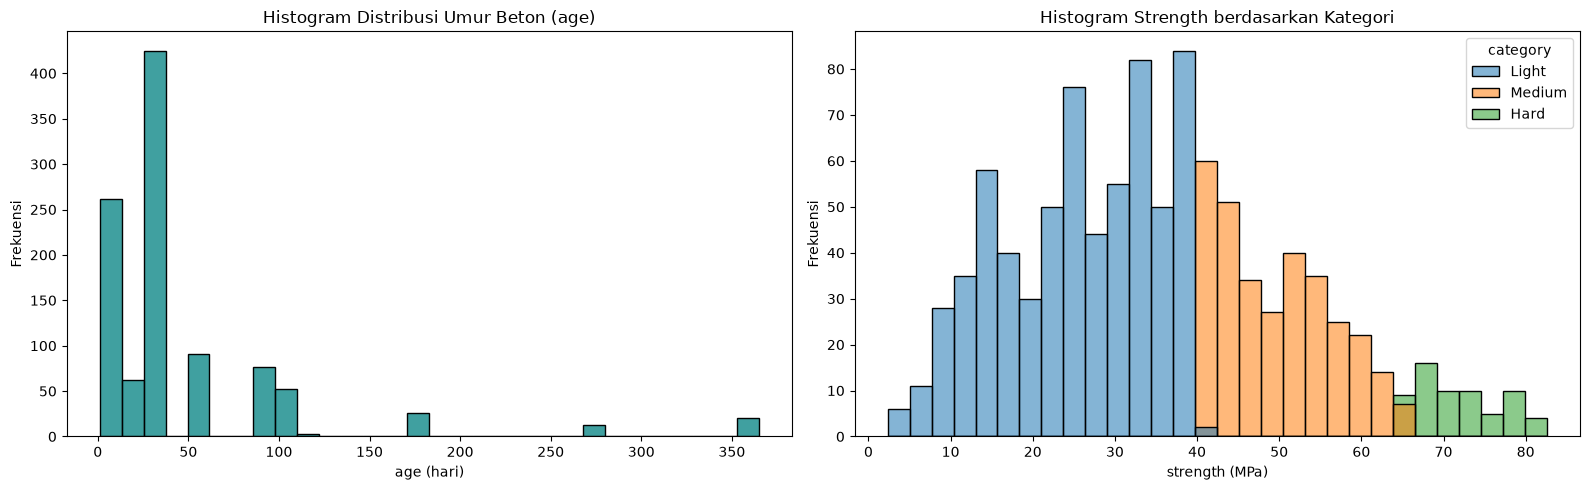

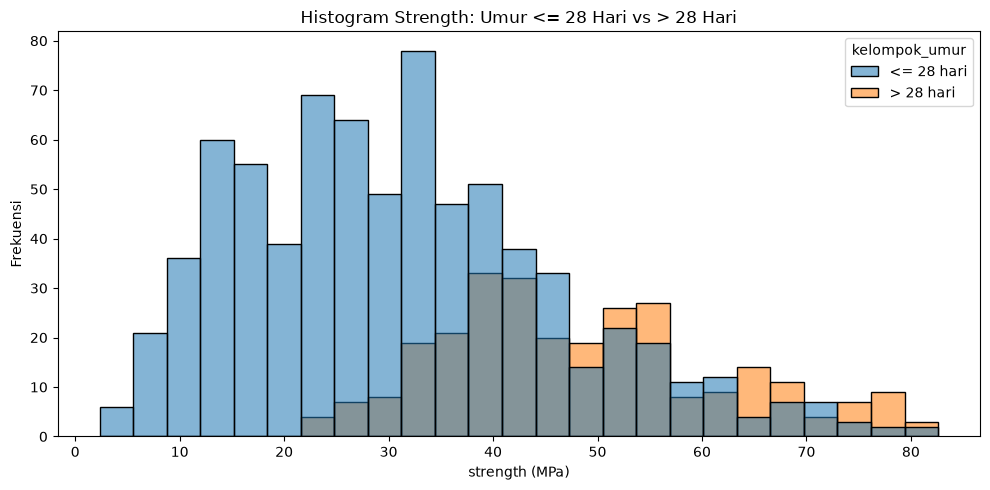

In [12]:
# Analisis histogram untuk pengaruh kolom 'age' terhadap kolom 'strength'
import matplotlib.pyplot as plt
import seaborn as sns

# Statistik ringkas
tabel_umur = concrete.groupby('age')['strength'].agg(
    jumlah='count', rata_rata='mean', minimum='min', maksimum='max'
).round(2)
print("Statistik strength berdasarkan umur:")
print(tabel_umur)

print(f"\nKorelasi Pearson  age vs strength: {concrete['age'].corr(concrete['strength']):.3f}")
print(f"Korelasi Spearman age vs strength: {concrete['age'].corr(concrete['strength'], method='spearman'):.3f}")

# Visualisasi histogram
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram umur
sns.histplot(data=concrete, x='age', bins=30, color='teal', ax=axes[0])
axes[0].set_title('Histogram Distribusi Umur Beton (age)')
axes[0].set_xlabel('age (hari)')
axes[0].set_ylabel('Frekuensi')

# Histogram strength dipisahkan oleh kategori kekuatan
sns.histplot(data=concrete, x='strength', hue='category',
             hue_order=['Light', 'Medium', 'Hard'], bins=30,
             alpha=0.55, ax=axes[1])
axes[1].set_title('Histogram Strength berdasarkan Kategori')
axes[1].set_xlabel('strength (MPa)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

# Histogram strength untuk kelompok umur muda dan tua
concrete['kelompok_umur'] = np.where(concrete['age'] <= 28, '<= 28 hari', '> 28 hari')
plt.figure(figsize=(10, 5))
sns.histplot(data=concrete, x='strength', hue='kelompok_umur', bins=25, alpha=0.55)
plt.title('Histogram Strength: Umur <= 28 Hari vs > 28 Hari')
plt.xlabel('strength (MPa)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

**Kesimpulan berdasarkan analisis histogram:**

1. **Histogram `age` menunjukkan distribusi yang tidak merata (right-skewed).** Sebagian besar data berada pada umur muda, terutama **28 hari (425 data)**, 3 hari (134 data), 7 hari (126 data), 56 hari (91 data), dan 14 hari (62 data). Data umur 90 hari ke atas sangat sedikit.
2. **Rata-rata `strength` naik seiring bertambahnya umur:** 9,46 MPa (1 hari) → 18,98 MPa (3 hari) → 26,05 MPa (7 hari) → 28,75 MPa (14 hari) → 36,75 MPa (28 hari) → 51,89 MPa (56 hari) → 69,81 MPa (91 hari). Ini membuktikan umur perawatan berpengaruh positif terhadap kekuatan.
3. **Histogram `strength` kelompok umur > 28 hari bergeser ke kanan** dibanding kelompok ≤ 28 hari, sehingga pada umur lebih tua proporsi beton berkekuatan `Medium`/`Hard` lebih banyak.
4. **Korelasi `age`–`strength` positif namun tidak linear sempurna** (Pearson **0,329**; Spearman **0,596**). Pola kenaikannya menyerupai logaritmik: strength meningkat cepat pada 28 hari pertama, lalu melandai. Setelah 90 hari penambahan strength relatif kecil dan tidak konsisten karena jumlah sampel sedikit serta komposisi campurannya berbeda-beda.
5. **Kesimpulannya, `age` berpengaruh nyata terhadap `strength`, tetapi bukan satu-satunya faktor.** Umur harus dianalisis bersama komposisi bahan (semen, air, dan bahan tambahan) untuk menjelaskan kekuatan beton secara menyeluruh.

### No 3.

In [13]:
# Komposisi concrete yang memiliki kekuatan tertinggi dan terendah
kolom_komposisi = ['cement', 'slag', 'ash', 'water', 'superplastic',
                   'coarseagg', 'fineagg', 'age', 'strength']

data_max = concrete.loc[concrete['strength'].idxmax(), kolom_komposisi]
data_min = concrete.loc[concrete['strength'].idxmin(), kolom_komposisi]

tabel = pd.DataFrame({
    'Tertinggi (Hard)': data_max,
    'Terendah (Light)': data_min
})
tabel.index.name = 'Komponen'

print(f"Strength tertinggi : {data_max['strength']} MPa")
print(f"Strength terendah  : {data_min['strength']} MPa\n")
print("Perbandingan komposisi concrete:")
print(tabel.to_string())

print("\nRasio air/semen (water/cement):")
print((tabel.loc['water'] / tabel.loc['cement']).round(3).to_string())

# Lima komposisi terkuat dan terlemah sebagai pembanding
print("\n=== 5 komposisi dengan strength TERTINGGI ===")
print(concrete.nlargest(5, 'strength')[kolom_komposisi].to_string())

print("\n=== 5 komposisi dengan strength TERENDAH ===")
print(concrete.nsmallest(5, 'strength')[kolom_komposisi].to_string())

print("\n=== Rata-rata komposisi berdasarkan kategori ===")
print(concrete.groupby('category', observed=True)[kolom_komposisi].mean().round(2).T)

Strength tertinggi : 82.6 MPa
Strength terendah  : 2.33 MPa

Perbandingan komposisi concrete:
              Tertinggi (Hard)  Terendah (Light)
Komponen                                        
cement                   389.9            108.30
slag                     189.0            162.40
ash                        0.0              0.00
water                    145.9            203.50
superplastic              22.0              0.00
coarseagg                944.7            938.20
fineagg                  755.8            849.00
age                       91.0              3.00
strength                  82.6              2.33

Rasio air/semen (water/cement):
Tertinggi (Hard)    0.374
Terendah (Light)    1.879

=== 5 komposisi dengan strength TERTINGGI ===
      cement   slag  ash  water  superplastic  coarseagg  fineagg  age  strength
950    389.9  189.0  0.0  145.9          22.0      944.7    755.8   91     82.60
192    315.0  137.0  0.0  145.0           5.9     1130.0    745.0   28   

### No 4.

**Kesimpulan akhir terhadap pengaruh komposisi concrete:**

1. **Komposisi dengan kekuatan tertinggi (82,6 MPa)** menggunakan semen 389,9 kg, slag 189,0 kg, ash 0 kg, air 145,9 kg, superplasticizer 22,0 kg, agregat kasar 944,7 kg, agregat halus 755,8 kg, pada umur 91 hari, dengan rasio air/semen **0,37**.
2. **Komposisi dengan kekuatan terendah (2,33 MPa)** memakai semen hanya 108,3 kg, slag 162,4 kg, ash 0 kg, air 203,5 kg, tanpa superplasticizer, agregat kasar 938,2 kg, agregat halus 849,0 kg, pada umur 3 hari, dengan rasio air/semen **1,88**.
3. **Semen adalah komponen yang paling menentukan kekuatan.** Rata-rata pemakaian semen pada beton `Hard` 397,13 kg, `Medium` 326,44 kg, dan `Light` 247,86 kg. Semakin banyak semen, semakin banyak pasta semen yang mengikat agregat sehingga beton semakin kuat.
4. **Rasio air/semen berbanding terbalik dengan kekuatan.** Air berlebih akan meninggalkan pori-pori setelah penguapan sehingga beton menjadi lemah. Pada data terlihat rata-rata air beton `Hard` 162,11 kg dan `Light` 185,31 kg, sementara rasio air/semen terendah menghasilkan strength tertinggi.
5. **Superplasticizer membantu meningkatkan kekuatan** karena mengurangi kebutuhan air. Rata-ratanya 11,15 kg pada kategori `Hard`, 7,91 kg pada `Medium`, dan 4,89 kg pada `Light`.
6. **Fly ash (`ash`) dosis besar tanpa diimbangi semen** banyak ditemukan pada beton `Light` (rata-rata 58,62 kg) dibanding beton `Hard` (16,67 kg), sehingga pada dataset ini fly ash berlebihan cenderung menurunkan kekuatan. Slag memiliki pola yang lebih seimbang dan pada kadar tertentu dapat membantu kekuatan (rata-rata 124,98 kg pada `Hard`).
7. **Agregat kasar dan agregat halus nilainya relatif stabil** pada semua kategori (agregat kasar sekitar 947–980 kg dan agregat halus sekitar 760–781 kg), sehingga keduanya bukan pembeda utama kekuatan pada dataset ini. Proporsi agregat yang wajar tetap diperlukan agar campuran mudah dikerjakan dan tidak berongga.
8. **Umur perawatan (`age`) juga berpengaruh positif**, dengan kenaikan strength terbesar pada 28 hari pertama (Spearman 0,596). Namun beton berumur tua tetap dapat lemah apabila semennya sedikit dan airnya berlebihan, seperti pada data strength terendah yang diuji pada umur 3 hari.

**Kesimpulan:** kekuatan beton ditentukan oleh kombinasi komposisi, terutama **kadar semen**, **rasio air/semen**, dan **bahan tambahan** (superplasticizer, slag, fly ash), serta didukung oleh **umur perawatan**. Komposisi dengan semen tinggi, air terkendali, dan superplasticizer memadai menghasilkan beton `Hard`, sedangkan semen rendah dengan air berlebih menghasilkan beton `Light`.

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">[VIDEO]</a>
    </div>



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma 


https://www.praktikum-hpc.gunadarma.ac.id/